# Task 2 Multiclass classification Baseline

In this class, we will develop a baseline for Task 2 using the chess dataset. We will model the task as an multiclass classification task.

In [1]:
import matplotlib.pyplot as plt, numpy as np, os, torch, random, cv2, json
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
from torchvision import models
from torchvision.transforms import v2 as transforms
from sklearn.metrics import accuracy_score
from tqdm import tqdm

random.seed(42)

### Connect Colab to Drive (if the dataset is on drive)

In [2]:
isDatasetOnDrive = False
path=""
if isDatasetOnDrive:
    path = "drive/MyDrive/VCOM/Dataset/"

In [3]:
if isDatasetOnDrive:
    from google.colab import drive
    drive.mount('/content/drive')

In [3]:
!unzip "drive/MyDrive/VCOM/Dataset/chessred/images.zip" -d "."
!cp "drive/MyDrive/VCOM/Dataset/chessred/annotations.json" -d "."

unzip:  cannot find or open drive/MyDrive/VCOM/Dataset/chessred/images.zip, drive/MyDrive/VCOM/Dataset/chessred/images.zip.zip or drive/MyDrive/VCOM/Dataset/chessred/images.zip.ZIP.
cp: cannot stat 'drive/MyDrive/VCOM/Dataset/chessred/annotations.json': No such file or directory


## Load dataset

**Tip**: since the images are very big, resize the dataset before loading it to save time and memory during training (use cubic interpolation to preserve image quality when downsizing the images)!

In [36]:
# Normalize images
data_aug = transforms.Compose([
    transforms.ToImage(),
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

data_in = transforms.Compose([
    transforms.ToImage(),
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [37]:
def chesspos2number(chesspos):
    col = ord(chesspos[0])-ord('a')
    row = int(chesspos[1])-1
    return row, col

class ChessDataset(Dataset):
    def __init__(self, root_dir, partition, transform=None):
        self.anns = json.load(open(os.path.join(root_dir, 'annotations.json')))
        self.categories = [c['name'] for c in self.anns['categories']]
        self.root = root_dir
        self.ids = []
        self.file_names = []
        for x in self.anns['images']:
            self.file_names.append(x['path'])
            self.ids.append(x['id'])
        self.file_names = np.asarray(self.file_names)
        self.ids = np.asarray(self.ids)
        self.boards = torch.zeros((len(self.file_names), 8, 8))
        for piece in self.anns['annotations']['pieces']:
            idx = np.where(self.ids == piece['image_id'])[0][0]
            row, col = chesspos2number(piece['chessboard_position'])
            self.boards[idx][row][col] = 1

        if partition == 'train':
            self.split_ids = np.asarray(self.anns['splits']['chessred2k']['train']['image_ids']).astype(int)
        elif partition == 'valid':
            self.split_ids = np.asarray(self.anns['splits']['chessred2k']['val']['image_ids']).astype(int)
        else:
            self.split_ids = np.asarray(self.anns['splits']['chessred2k']['test']['image_ids']).astype(int)

        intersect = np.isin(self.ids, self.split_ids)
        self.split_ids = np.where(intersect)[0]
        self.file_names = self.file_names[self.split_ids]
        self.boards = self.boards[self.split_ids]
        self.num_pieces = torch.sum(self.boards.view(len(self.boards), 64), axis=-1)
        self.num_pieces = F.one_hot(self.num_pieces.long()-1, 32)
        self.ids = self.ids[self.split_ids]
        self.images = []
        for (i, file_name) in enumerate(self.file_names):
            image = cv2.imread(os.path.join(self.root, file_name))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            self.images.append(image)
            if i % 1000 == 0:
                print(f"Loaded {i} images")

        self.transform = transform
        print(f"Number of {partition} images: {len(self.file_names)}")

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, i):
        image = self.images[i]

        if self.transform:
            image = self.transform(image)

        num_pieces = self.num_pieces[i]

        return image, num_pieces.float()

train_dataset = ChessDataset('', 'train', data_aug)
valid_dataset = ChessDataset('', 'valid', data_in)
test_dataset = ChessDataset('', 'test', data_in)

Loaded 0 images
Loaded 1000 images
Number of train images: 1442
Loaded 0 images
Number of valid images: 330
Loaded 0 images
Number of test images: 306


In [38]:
# get cpu or gpu device for training
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

# now we need to define a Dataloader, which allows us to automatically batch our inputs, do sampling and multiprocess data loading
batch_size = 16
num_workers = 2 # how many processes are used to load the data

train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, drop_last=False)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, drop_last=False)

Using cuda device


torch.Size([16, 224, 224, 3])
torch.Size([16, 32])
tensor(29)


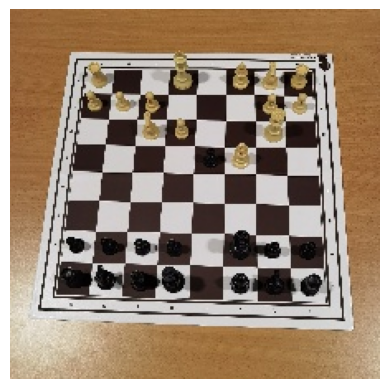

In [39]:
for batch in train_dataloader:
    # Get images of the batch and print their dimensions
    imgs = batch[0]
    imgs = imgs.permute(0, 2, 3, 1)*torch.tensor([[[0.229, 0.224, 0.225]]]) + torch.tensor([[[0.485, 0.456, 0.406]]])
    print(imgs.shape)

    # Get labels of each image in the batch and print them
    labels = batch[1]
    print(labels.shape)
    print(torch.argmax(labels)+1)

    # Show first image of the batch
    plt.imshow(imgs[0])
    plt.axis('off')
    plt.show()

    break

## Defining the model

We will use a pre-trained ResNet50 network.

In [40]:
# Get cpu or gpu device for training.
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

# Define model
model = models.resnet50(pretrained=True)
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

# change the number of neurons in the last layer to the number of classes of the problem at hand (maximum number of pieces on a chess game)
model.fc = nn.Linear(2048, 32)

model.to(device)

Using cuda device


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## Train the model

In [41]:
def load_checkpoint(model, optimizer, checkpoint_path):
    checkpoint = torch.load(checkpoint_path)
    model.load_state_dict(checkpoint['model'])
    optimizer.load_state_dict(checkpoint['optimizer'])
    start_epoch = checkpoint['epoch'] + 1
    train_history = checkpoint.get('train_history', {'loss': [], 'accuracy': []})
    val_history = checkpoint.get('val_history', {'loss': [], 'accuracy': []})
    best_val_loss = checkpoint.get('best_val_loss', np.inf)
    print(f"Resumed from checkpoint at epoch {checkpoint['epoch']}")
    return model, optimizer, start_epoch, train_history, val_history, best_val_loss

Define function to perform one iteration

In [42]:
from sklearn.metrics import accuracy_score, mean_squared_error, mean_absolute_error

def epoch_iter(dataloader, model, loss_fn, optimizer=None, is_train=True):
    if is_train:
        assert optimizer is not None, "When training, please provide an optimizer."

    num_batches = len(dataloader)

    model.train() if is_train else model.eval()

    total_loss = 0.0
    preds = []
    labels = []

    with torch.set_grad_enabled(is_train):
        for batch, (X, y) in enumerate(tqdm(dataloader)):
            X, y = X.to(device), y.to(device)

            pred = model(X)
            loss = loss_fn(pred, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()

            if y.ndim > 1 and y.size(1) > 1:
                y = torch.argmax(y, dim=1)
            pred_labels = torch.argmax(pred, dim=1)
            preds.extend(pred_labels.cpu().numpy())
            labels.extend(y.cpu().numpy())

    avg_loss = total_loss / num_batches

    metric = accuracy_score(labels, preds)

    return avg_loss, metric


Define function to train a model

In [43]:
def train(model, model_name, num_epochs, train_dataloader, validation_dataloader, loss_fn, optimizer, resume=False):
    checkpoint_path = model_name + '_latest_model.pth'

    # Initialize or load
    if resume and os.path.exists(checkpoint_path):
        model, optimizer, start_epoch, train_history, val_history, best_val_loss = load_checkpoint(model, optimizer, checkpoint_path)
    else:
        start_epoch = 0
        train_history = {'loss': [], 'accuracy': []}
        val_history = {'loss': [], 'accuracy': []}
        best_val_loss = np.inf

    print("Start training...")
    for t in range(start_epoch, num_epochs):
        print(f"\nEpoch {t+1}")
        train_loss, train_acc = epoch_iter(train_dataloader, model, loss_fn, optimizer)
        print(f"Train loss: {train_loss:.3f} \t Train acc: {train_acc:.3f}")
        val_loss, val_acc = epoch_iter(validation_dataloader, model, loss_fn, is_train=False)
        print(f"Val loss: {val_loss:.3f} \t Val acc: {val_acc:.3f}")

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_save_dict = {
                'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'epoch': t,
                'train_history': train_history,
                'val_history': val_history,
                'best_val_loss': best_val_loss
            }
            torch.save(best_save_dict, path + model_name + '_best_model.pth')
            torch.save(best_save_dict, model_name + '_best_model.pth')

        # Save latest model (every epoch)
        latest_save_dict = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': t,
            'train_history': train_history,
            'val_history': val_history,
            'best_val_loss': best_val_loss
        }
        torch.save(latest_save_dict, path + model_name + '_latest_model.pth')
        torch.save(latest_save_dict, model_name + '_latest_model.pth')

        # Append history
        train_history["loss"].append(train_loss)
        train_history["accuracy"].append(train_acc)
        val_history["loss"].append(val_loss)
        val_history["accuracy"].append(val_acc)

    print("Finished training.")
    return train_history, val_history

Define loss, optimizer and train the model

In [44]:
# Define loss function
loss_fn = nn.CrossEntropyLoss()

# Define optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

num_epochs = 50
global_results = {}

In [45]:
model_name = 'ResNet50'

train_history, val_history = train(model, model_name, num_epochs, train_dataloader, valid_dataloader, loss_fn, optimizer)

Start training...

Epoch 1


100%|██████████| 90/90 [00:05<00:00, 17.76it/s]


Train loss: 3.285 	 Train acc: 0.092


100%|██████████| 21/21 [00:01<00:00, 18.15it/s]


Val loss: 3.388 	 Val acc: 0.106

Epoch 2


100%|██████████| 90/90 [00:05<00:00, 17.74it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:05<00:00, 17.81it/s]


Train loss: 2.441 	 Train acc: 0.307


100%|██████████| 21/21 [00:01<00:00, 18.08it/s]


Val loss: 3.404 	 Val acc: 0.145
Finished training.


In [46]:
def saveHistory(train_history, val_history, model_name):
    # Create a dict with train_history, validation_history and the save_dict
    save_dict = torch.load(model_name + '_best_model.pth')
    history_dict = {
        'save_dict': save_dict,
        'train_history': train_history,
        'val_history': val_history
    }
    torch.save(history_dict, path + model_name + '_history.pth')


In [47]:
# Create a dict with train_history, validation_history and the save_dict
save_dict = torch.load(model_name + '_best_model.pth')
history_dict = {
    'train_history': train_history,
    'val_history': val_history,
    'save_dict': save_dict
}

# Save it to drive as backup
saveHistory(train_history, val_history, model_name)

## Analyse training evolution

Plot loss and accuracy throughout training on train and validation data

In [48]:
def plotTrainingHistory(train_history, val_history):
    plt.subplot(2, 1, 1)
    plt.title('Cross Entropy Loss')
    plt.plot(train_history['loss'], label='train')
    plt.plot(val_history['loss'], label='val')
    plt.legend(loc='best')

    plt.subplot(2, 1, 2)
    plt.title('Classification Accuracy')
    plt.plot(train_history['accuracy'], label='train')
    plt.plot(val_history['accuracy'], label='val')

    plt.tight_layout()
    plt.legend(loc='best')
    plt.show()

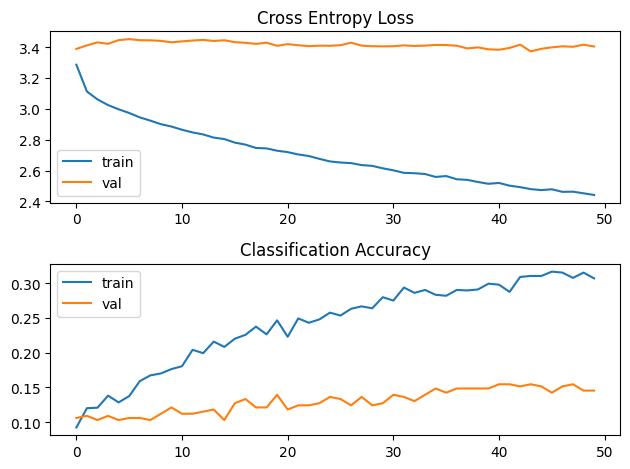

In [49]:
plotTrainingHistory(train_history, val_history)

## Fine tune the model

Get the best model and train it end-to-end

In [50]:
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])

# Unfreeze all layers
for param in model.parameters():
    param.requires_grad = True

model_name = 'ResNet50_finetuned'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train(model, model_name, num_epochs, train_dataloader, valid_dataloader, loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:13<00:00,  6.78it/s]


Train loss: 2.435 	 Train acc: 0.311


100%|██████████| 21/21 [00:01<00:00, 18.35it/s]


Val loss: 3.291 	 Val acc: 0.176

Epoch 2


100%|██████████| 90/90 [00:13<00:00,  6.80it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:13<00:00,  6.82it/s]


Train loss: 0.123 	 Train acc: 0.999


100%|██████████| 21/21 [00:01<00:00, 18.33it/s]


Val loss: 3.531 	 Val acc: 0.188
Finished training.


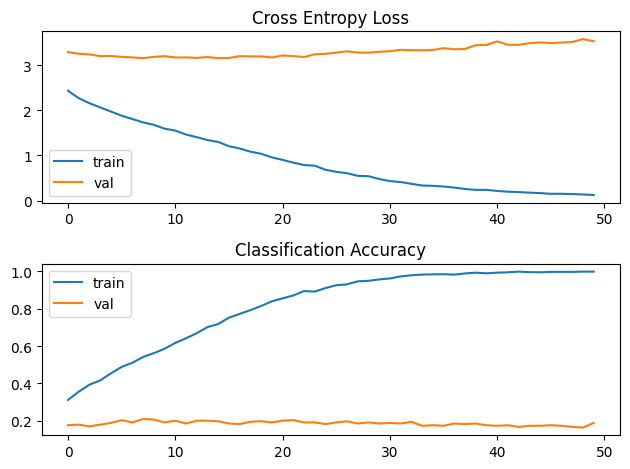

In [51]:
plotTrainingHistory(train_history, val_history)

## Test the model

Evaluate the model in the test set

In [52]:
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])

# Evaluate model on test data
test_loss, test_acc = epoch_iter(test_dataloader, model, loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

100%|██████████| 20/20 [00:01<00:00, 18.19it/s]

Test loss: 2.507 	 Test acc: 0.327


## EfficientNetB2 classification

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B2_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Start training...

Epoch 1


100%|██████████| 90/90 [00:03<00:00, 24.94it/s]


Train loss: 3.450 	 Train acc: 0.045


100%|██████████| 21/21 [00:00<00:00, 25.14it/s]


Val loss: 3.414 	 Val acc: 0.070

Epoch 2


... (192 outputs left out)

100%|██████████| 90/90 [00:03<00:00, 25.29it/s]


Train loss: 2.768 	 Train acc: 0.231


100%|██████████| 21/21 [00:00<00:00, 25.81it/s]


Val loss: 3.237 	 Val acc: 0.130
Finished training.


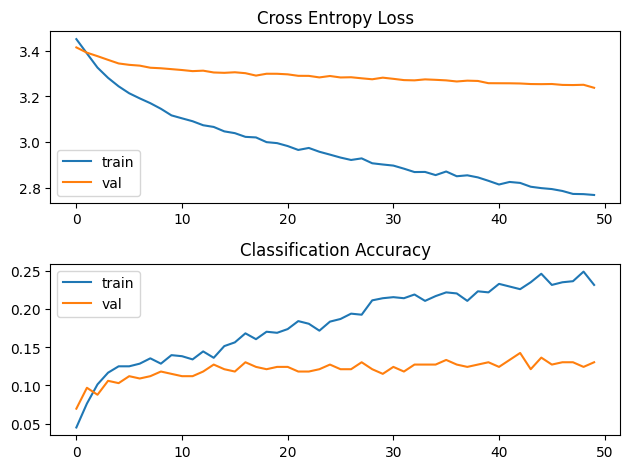

Start training...

Epoch 1


100%|██████████| 90/90 [00:11<00:00,  7.77it/s]


Train loss: 2.736 	 Train acc: 0.243


100%|██████████| 21/21 [00:00<00:00, 26.10it/s]


Val loss: 3.227 	 Val acc: 0.124

Epoch 2


100%|██████████| 90/90 [00:11<00:00,  7.77it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:11<00:00,  7.74it/s]


Train loss: 1.729 	 Train acc: 0.492


100%|██████████| 21/21 [00:00<00:00, 25.81it/s]


Val loss: 2.841 	 Val acc: 0.221
Finished training.


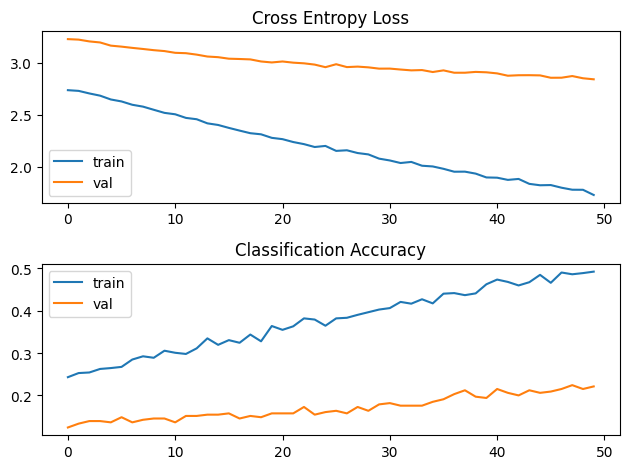

100%|██████████| 20/20 [00:00<00:00, 24.88it/s]

Test loss: 2.389 	 Test acc: 0.310


In [53]:
model = models.efficientnet_b2(pretrained=True)
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(1408, 32)

model.to(device)
model_name = 'EfficientNet_B2_classification'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train(model, model_name, num_epochs, train_dataloader, valid_dataloader, loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistory(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# finetune
for param in model.parameters():
    param.requires_grad = True
model_name = 'EfficientNet_B2_finetuned'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train(model, model_name, num_epochs, train_dataloader, valid_dataloader, loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistory(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# Evaluate model on test data
test_loss, test_acc = epoch_iter(test_dataloader, model, loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

## MobileNetV2 classification

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Start training...

Epoch 1


100%|██████████| 90/90 [00:02<00:00, 43.19it/s]


Train loss: 3.319 	 Train acc: 0.100


100%|██████████| 21/21 [00:00<00:00, 41.15it/s]


Val loss: 3.423 	 Val acc: 0.097

Epoch 2


... (192 outputs left out)

100%|██████████| 90/90 [00:02<00:00, 44.59it/s]


Train loss: 2.350 	 Train acc: 0.334


100%|██████████| 21/21 [00:00<00:00, 43.13it/s]


Val loss: 3.315 	 Val acc: 0.176
Finished training.


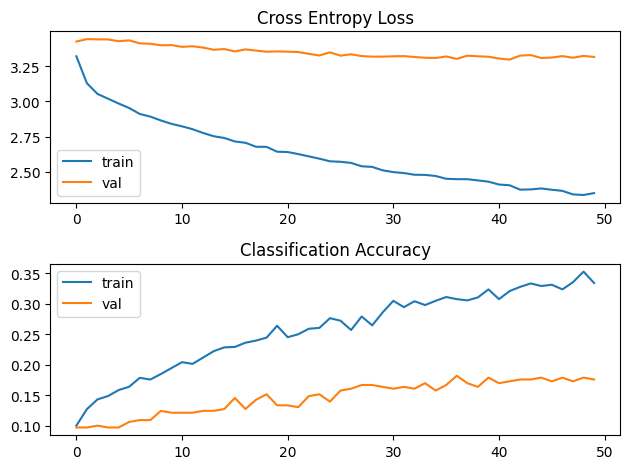

Start training...

Epoch 1


100%|██████████| 90/90 [00:05<00:00, 15.23it/s]


Train loss: 2.316 	 Train acc: 0.338


100%|██████████| 21/21 [00:00<00:00, 42.98it/s]


Val loss: 3.271 	 Val acc: 0.185

Epoch 2


100%|██████████| 90/90 [00:05<00:00, 15.25it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:05<00:00, 15.24it/s]


Train loss: 0.250 	 Train acc: 0.981


100%|██████████| 21/21 [00:00<00:00, 42.98it/s]


Val loss: 3.647 	 Val acc: 0.182
Finished training.


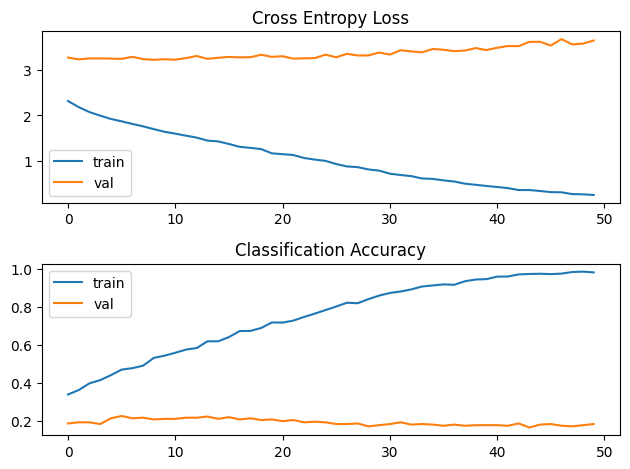

100%|██████████| 20/20 [00:00<00:00, 42.54it/s]

Test loss: 2.530 	 Test acc: 0.294


In [54]:
model = models.mobilenet_v2(pretrained=True)
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(1280, 32)

model.to(device)
model_name = 'MobileNetV2_classification'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train(model, model_name, num_epochs, train_dataloader, valid_dataloader, loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistory(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# finetune
for param in model.parameters():
    param.requires_grad = True
model_name = 'MobileNetV2_finetuned'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train(model, model_name, num_epochs, train_dataloader, valid_dataloader, loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistory(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# Evaluate model on test data
test_loss, test_acc = epoch_iter(test_dataloader, model, loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

## Challenge

In transfer learning, we often replace the head of the model (fully-connected layers responsible for classification) to fit the task. However, these new layers are not pre-trained and thus they contain an error that is backpropagated through the pre-trained part of the network during training. We can avoid this through a training strategy that is divided into two steps:
* Freeze the pre-trained layers of the network so that their parameters are no longer updated during training and train only the head of the model
* Unfreeze these layers and train the network as a whole.

Implement this strategy and see the results!

## For Group Project - Task 2: Adapt multiclass classification network to regression!

Now that you have a multiclass baseline, adapt the network for the regression problem, considering the following aspects:
* How many neurons should the last layer of a regression network have? - 1
* What should be the final activation function for a regression network? - Linear Activation function
* What loss functions can be used to train a regression network? - MSE and MAE

In [55]:
class ChessDatasetRegression(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset
        self.num_pieces = torch.sum(self.base_dataset.boards.view(len(self.base_dataset.boards), 64), axis=-1)


    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, i):
        image = self.base_dataset.images[i]

        if self.base_dataset.transform:
            image = self.base_dataset.transform(image)

        num_pieces = self.num_pieces[i]

        return image, num_pieces.float()


train_dataset_regression = ChessDatasetRegression(train_dataset)
valid_dataset_regression = ChessDatasetRegression(valid_dataset)
test_dataset_regression = ChessDatasetRegression(test_dataset)
train_dataloader = DataLoader(train_dataset_regression, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True)
valid_dataloader = DataLoader(valid_dataset_regression, batch_size=batch_size, shuffle=False, num_workers=num_workers, drop_last=False)
test_dataloader = DataLoader(test_dataset_regression, batch_size=batch_size, shuffle=False, num_workers=num_workers, drop_last=False)

In [56]:
def epoch_iter_regression(dataloader, model, loss_fn, optimizer=None, is_train=True):
    if is_train:
        assert optimizer is not None, "When training, please provide an optimizer."

    num_batches = len(dataloader)

    model.train() if is_train else model.eval()

    total_loss = 0.0
    preds = []
    labels = []

    with torch.set_grad_enabled(is_train):
        for batch, (X, y) in enumerate(tqdm(dataloader)):
            X, y = X.to(device), y.to(device)

            pred = model(X)
            pred = pred.squeeze(1)
            loss = loss_fn(pred, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()

            preds.extend(pred.detach().cpu().numpy())
            labels.extend(y.detach().cpu().numpy())

    avg_loss = total_loss / num_batches
    mse = mean_squared_error(labels, preds)
    mae = mean_absolute_error(labels, preds)
    accuracy = accuracy_score(labels, np.round(preds))

    return avg_loss, mse, mae, accuracy

In [57]:
def train_regression(model, model_name, num_epochs, train_dataloader, validation_dataloader, loss_fn, optimizer, resume=False):
    checkpoint_path = model_name + '_latest_model.pth'

    # Initialize or load
    if resume and os.path.exists(checkpoint_path):
        model, optimizer, start_epoch, train_history, val_history, best_val_loss = load_checkpoint(model, optimizer, checkpoint_path)
    else:
        start_epoch = 0
        train_history = {'loss': [], 'mse': [], 'mae': [], 'accuracy': []}
        val_history = {'loss': [], 'mse': [], 'mae': [], 'accuracy': []}
        best_val_loss = np.inf

    print("Start training...")
    for t in range(start_epoch, num_epochs):
        print(f"\nEpoch {t+1}")
        train_loss, train_mse, train_mae, train_acc= epoch_iter_regression(train_dataloader, model, loss_fn, optimizer)
        print(f"Train loss: {train_loss:.3f} \t Train mse: {train_mse:.3f} \t Train mae: {train_mae:.3f}, Train acc: {train_acc:.3f}")
        val_loss, val_mse, val_mae, val_acc= epoch_iter_regression(validation_dataloader, model, loss_fn, is_train=False)
        print(f"Val loss: {val_loss:.3f} \t Val mse: {val_mse:.3f} \t Val mae: {val_mae:.3f}, Val acc: {val_acc:.3f}")

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_save_dict = {
                'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'epoch': t,
                'train_history': train_history,
                'val_history': val_history,
                'best_val_loss': best_val_loss
            }
            torch.save(best_save_dict, path + model_name + '_best_model.pth')
            torch.save(best_save_dict, model_name + '_best_model.pth')

        # Save latest model (every epoch)
        latest_save_dict = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': t,
            'train_history': train_history,
            'val_history': val_history,
            'best_val_loss': best_val_loss
        }
        torch.save(latest_save_dict, path + model_name + '_latest_model.pth')
        torch.save(latest_save_dict, model_name + '_latest_model.pth')

        # Append history
        train_history["loss"].append(train_loss)
        train_history["mse"].append(train_mse)
        train_history["mae"].append(train_mae)
        train_history["accuracy"].append(train_acc)

        val_history["loss"].append(val_loss)
        val_history["mse"].append(val_mse)
        val_history["mae"].append(val_mae)
        val_history["accuracy"].append(val_acc)

    print("Finished training.")
    return train_history, val_history

In [58]:
def plotTrainingHistoryRegression(train_history, val_history):
    plt.subplot(3, 1, 1)
    plt.title('Regression MSE')
    plt.plot(train_history['mse'], label='train')
    plt.plot(val_history['mse'], label='val')
    plt.legend(loc='best')

    plt.subplot(3, 1, 2)
    plt.title('Regression MAE')
    plt.plot(train_history['mae'], label='train')
    plt.plot(val_history['mae'], label='val')
    plt.legend(loc='best')

    plt.subplot(3, 1, 3)
    plt.title('Regression Accuracy')
    plt.plot(train_history['accuracy'], label='train')
    plt.plot(val_history['accuracy'], label='val')

    plt.tight_layout()
    plt.legend(loc='best')
    plt.show()

## ResNet50 from multiclass


In [59]:
# ResNet50 for regression starting from multiclass

model = models.resnet50(pretrained=True)
model.fc = nn.Linear(2048, 32)
# load the best model
model.load_state_dict(torch.load('ResNet50_finetuned_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(2048, 1)

model.to(device)
regression_loss_fn = nn.MSELoss()

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


torch.Size([16, 224, 224, 3])
torch.Size([16])
tensor([30., 29., 12., 16., 27., 17., 22., 21., 17., 29., 17., 22., 13., 26.,
        10., 25.])


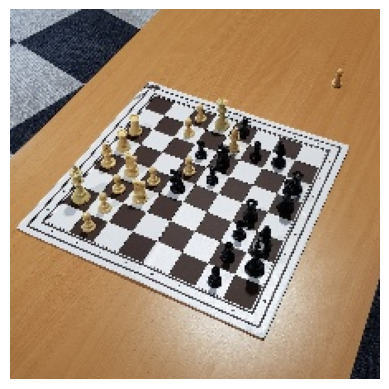

In [60]:
# New loss function
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
model_name = 'ResNet50_regression_base_multiclass'
for batch in train_dataloader:
    # Get images of the batch and print their dimensions
    imgs = batch[0]
    imgs = imgs.permute(0, 2, 3, 1)*torch.tensor([[[0.229, 0.224, 0.225]]]) + torch.tensor([[[0.485, 0.456, 0.406]]])
    print(imgs.shape)

    # Get labels of each image in the batch and print them
    labels = batch[1]
    print(labels.shape)
    print(labels)

    # Show first image of the batch
    plt.imshow(imgs[0])
    plt.axis('off')
    plt.show()

    break

In [61]:
# Train
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:05<00:00, 17.95it/s]


Train loss: 20.999 	 Train mse: 20.999 	 Train mae: 3.237, Train acc: 0.113


100%|██████████| 21/21 [00:01<00:00, 18.16it/s]


Val loss: 10.275 	 Val mse: 10.281 	 Val mae: 2.647, Val acc: 0.112

Epoch 2


100%|██████████| 90/90 [00:05<00:00, 17.96it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:05<00:00, 17.87it/s]


Train loss: 6.502 	 Train mse: 6.502 	 Train mae: 2.051, Train acc: 0.147


100%|██████████| 21/21 [00:01<00:00, 17.96it/s]


Val loss: 7.196 	 Val mse: 7.178 	 Val mae: 2.207, Val acc: 0.097
Finished training.


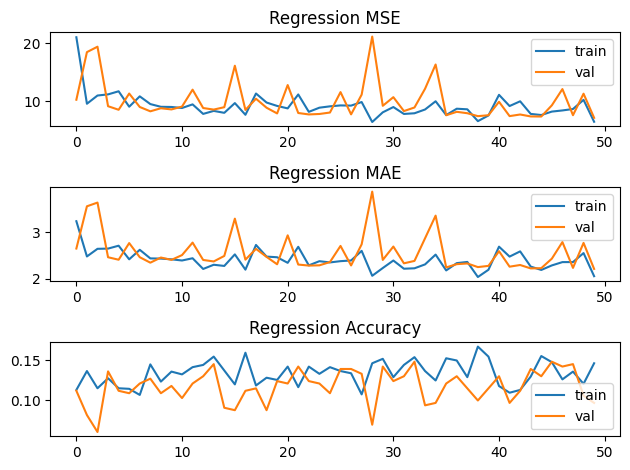

In [62]:
plotTrainingHistoryRegression(train_history, val_history)

In [63]:
# Fine tune
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = True

model_name = 'ResNet50_regression_base_multiclass_finetune'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:13<00:00,  6.77it/s]


Train loss: 15.484 	 Train mse: 15.484 	 Train mae: 2.991, Train acc: 0.118


100%|██████████| 21/21 [00:01<00:00, 17.96it/s]


Val loss: 4.248 	 Val mse: 4.206 	 Val mae: 1.603, Val acc: 0.206

Epoch 2


100%|██████████| 90/90 [00:13<00:00,  6.77it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:13<00:00,  6.80it/s]


Train loss: 0.196 	 Train mse: 0.196 	 Train mae: 0.348, Train acc: 0.761


100%|██████████| 21/21 [00:01<00:00, 18.08it/s]


Val loss: 3.675 	 Val mse: 3.592 	 Val mae: 1.582, Val acc: 0.176
Finished training.


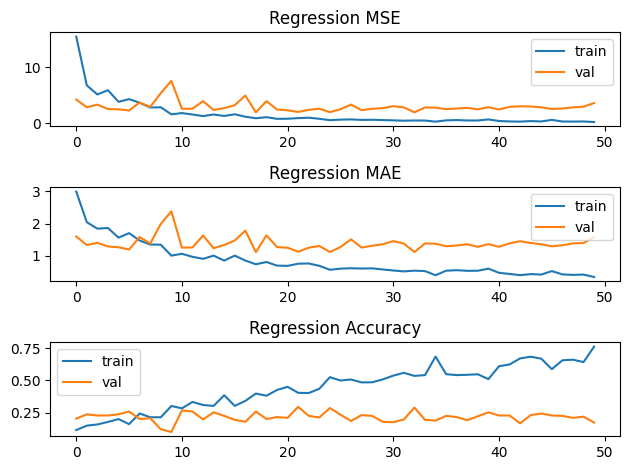

In [64]:
plotTrainingHistoryRegression(train_history, val_history)

In [65]:
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])

# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

100%|██████████| 20/20 [00:01<00:00, 18.54it/s]

Test loss: 2.009 	 Test mse: 2.088 	 Test mae: 1.171, Test acc: 0.242


## ResNet50 from base resnet

In [66]:
# ResNet50 for regression starting from resnet
model = models.resnet50(pretrained=True)
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(2048, 1)

model.to(device)
model_name = 'ResNet50_regression_base_resnet50'

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [67]:
# Train
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:05<00:00, 17.94it/s]


Train loss: 54.486 	 Train mse: 54.486 	 Train mae: 6.163, Train acc: 0.037


100%|██████████| 21/21 [00:01<00:00, 18.26it/s]


Val loss: 52.940 	 Val mse: 52.161 	 Val mae: 6.315, Val acc: 0.048

Epoch 2


100%|██████████| 90/90 [00:05<00:00, 17.87it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:05<00:00, 17.96it/s]


Train loss: 13.651 	 Train mse: 13.651 	 Train mae: 2.958, Train acc: 0.108


100%|██████████| 21/21 [00:01<00:00, 18.25it/s]


Val loss: 20.823 	 Val mse: 20.884 	 Val mae: 3.697, Val acc: 0.073
Finished training.


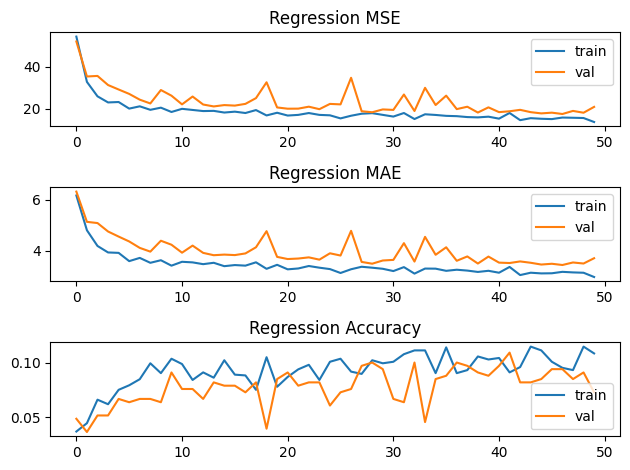

In [68]:
plotTrainingHistoryRegression(train_history, val_history)

In [69]:
# Fine tune
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = True

model_name = 'ResNet50_regression_base_resnet50_finetune'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:13<00:00,  6.81it/s]


Train loss: 29.108 	 Train mse: 29.108 	 Train mae: 3.594, Train acc: 0.124


100%|██████████| 21/21 [00:01<00:00, 18.14it/s]


Val loss: 7.410 	 Val mse: 7.381 	 Val mae: 2.225, Val acc: 0.133

Epoch 2


100%|██████████| 90/90 [00:13<00:00,  6.81it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:13<00:00,  6.81it/s]


Train loss: 0.350 	 Train mse: 0.350 	 Train mae: 0.475, Train acc: 0.600


100%|██████████| 21/21 [00:01<00:00, 18.10it/s]


Val loss: 2.733 	 Val mse: 2.672 	 Val mae: 1.365, Val acc: 0.191
Finished training.


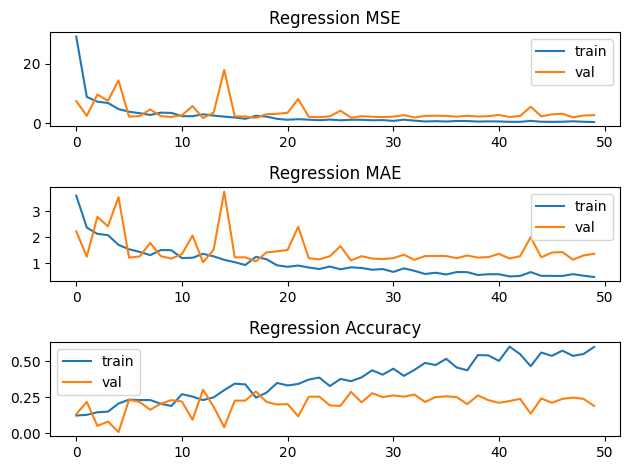

In [70]:
plotTrainingHistoryRegression(train_history, val_history)

In [71]:
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])

# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

100%|██████████| 20/20 [00:01<00:00, 18.61it/s]

Test loss: 1.772 	 Test mse: 1.844 	 Test mae: 1.075, Test acc: 0.281


## EfficientNet B2

In [72]:
model = models.efficientnet_b2(pretrained=True)
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(1408, 1)

model.to(device)
model_name = 'EfficientNet_B2_regression'

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B2_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [73]:
# Train
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:03<00:00, 25.18it/s]


Train loss: 120.223 	 Train mse: 120.223 	 Train mae: 8.788, Train acc: 0.032


100%|██████████| 21/21 [00:00<00:00, 25.59it/s]


Val loss: 86.585 	 Val mse: 87.572 	 Val mae: 7.558, Val acc: 0.039

Epoch 2


100%|██████████| 90/90 [00:03<00:00, 25.48it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:03<00:00, 25.32it/s]


Train loss: 26.616 	 Train mse: 26.616 	 Train mae: 4.156, Train acc: 0.075


100%|██████████| 21/21 [00:00<00:00, 25.47it/s]


Val loss: 29.902 	 Val mse: 29.577 	 Val mae: 4.408, Val acc: 0.070
Finished training.


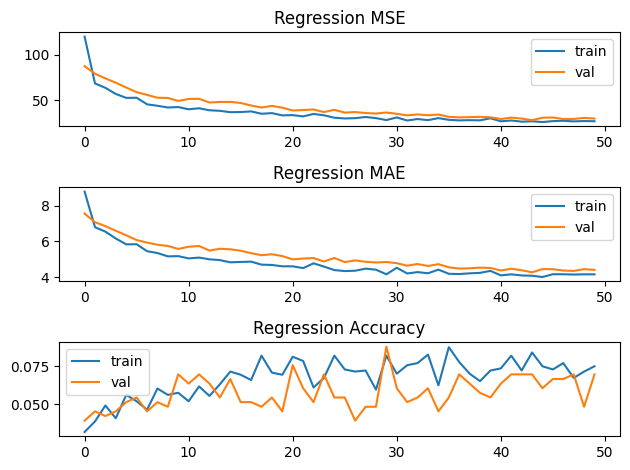

In [74]:
plotTrainingHistoryRegression(train_history, val_history)

In [75]:
# Fine tune
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = True

model_name = 'EfficientNet_B2_regression_finetune'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:11<00:00,  7.75it/s]


Train loss: 26.619 	 Train mse: 26.619 	 Train mae: 4.061, Train acc: 0.075


100%|██████████| 21/21 [00:00<00:00, 25.10it/s]


Val loss: 12.243 	 Val mse: 12.412 	 Val mae: 2.849, Val acc: 0.115

Epoch 2


100%|██████████| 90/90 [00:11<00:00,  7.71it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:11<00:00,  7.72it/s]


Train loss: 0.904 	 Train mse: 0.904 	 Train mae: 0.753, Train acc: 0.401


100%|██████████| 21/21 [00:00<00:00, 25.05it/s]


Val loss: 2.682 	 Val mse: 2.722 	 Val mae: 1.319, Val acc: 0.267
Finished training.


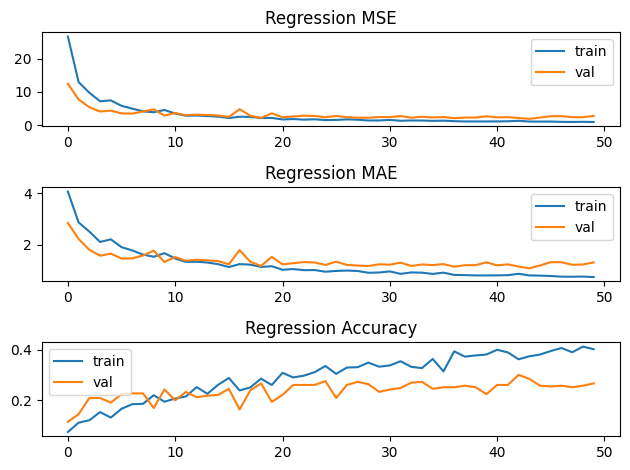

In [76]:
plotTrainingHistoryRegression(train_history, val_history)

In [77]:
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])

# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

100%|██████████| 20/20 [00:00<00:00, 25.14it/s]

Test loss: 1.611 	 Test mse: 1.641 	 Test mae: 1.014, Test acc: 0.330


## MobileNet V2

In [78]:
model = models.mobilenet_v2(pretrained=True)
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(1280, 1)

model.to(device)
model_name = 'MobileNet_V2_regression'

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [79]:
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:02<00:00, 43.61it/s]


Train loss: 46.298 	 Train mse: 46.298 	 Train mae: 5.573, Train acc: 0.049


100%|██████████| 21/21 [00:00<00:00, 41.19it/s]


Val loss: 32.634 	 Val mse: 32.154 	 Val mae: 4.848, Val acc: 0.042

Epoch 2


100%|██████████| 90/90 [00:02<00:00, 43.04it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:02<00:00, 44.63it/s]


Train loss: 16.861 	 Train mse: 16.861 	 Train mae: 3.246, Train acc: 0.101


100%|██████████| 21/21 [00:00<00:00, 41.26it/s]


Val loss: 12.950 	 Val mse: 12.927 	 Val mae: 2.850, Val acc: 0.115
Finished training.


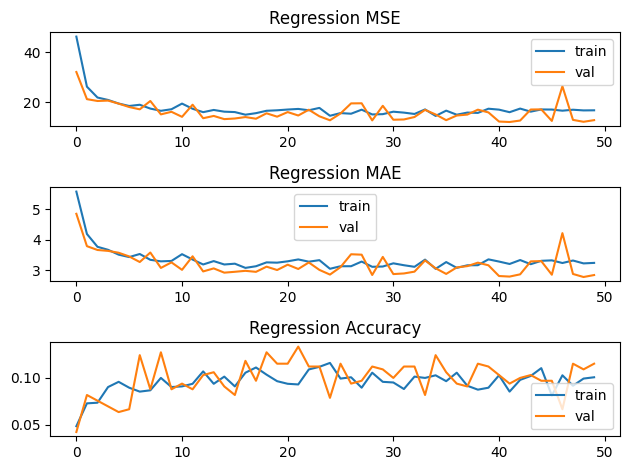

In [80]:
plotTrainingHistoryRegression(train_history, val_history)

In [81]:
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = True

model_name = 'MobileNet_V2_regression_finetune'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)

Start training...

Epoch 1


100%|██████████| 90/90 [00:05<00:00, 15.23it/s]


Train loss: 35.564 	 Train mse: 35.564 	 Train mae: 4.259, Train acc: 0.094


100%|██████████| 21/21 [00:00<00:00, 43.56it/s]


Val loss: 6.713 	 Val mse: 6.646 	 Val mae: 2.061, Val acc: 0.152

Epoch 2


100%|██████████| 90/90 [00:05<00:00, 15.21it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:05<00:00, 15.14it/s]


Train loss: 1.447 	 Train mse: 1.447 	 Train mae: 0.965, Train acc: 0.322


100%|██████████| 21/21 [00:00<00:00, 42.00it/s]


Val loss: 2.540 	 Val mse: 2.511 	 Val mae: 1.254, Val acc: 0.270
Finished training.


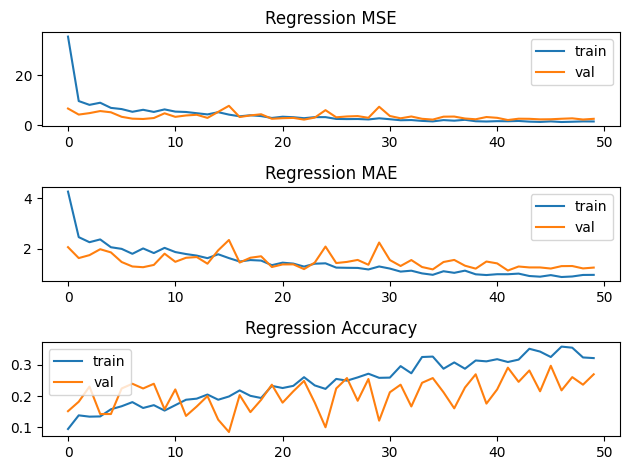

In [82]:
plotTrainingHistoryRegression(train_history, val_history)

In [83]:
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])

# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

100%|██████████| 20/20 [00:00<00:00, 41.91it/s]

Test loss: 2.114 	 Test mse: 2.211 	 Test mae: 1.112, Test acc: 0.304


## EfficientNet B2 from multiclass

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B2_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Start training...

Epoch 1


100%|██████████| 90/90 [00:03<00:00, 25.17it/s]


Train loss: 70.899 	 Train mse: 70.899 	 Train mae: 6.410, Train acc: 0.052


100%|██████████| 21/21 [00:00<00:00, 25.42it/s]


Val loss: 56.417 	 Val mse: 56.845 	 Val mae: 6.294, Val acc: 0.036

Epoch 2


... (192 outputs left out)

100%|██████████| 90/90 [00:03<00:00, 25.00it/s]


Train loss: 16.252 	 Train mse: 16.252 	 Train mae: 3.207, Train acc: 0.094


100%|██████████| 21/21 [00:00<00:00, 24.77it/s]


Val loss: 15.443 	 Val mse: 15.665 	 Val mae: 3.130, Val acc: 0.097
Finished training.


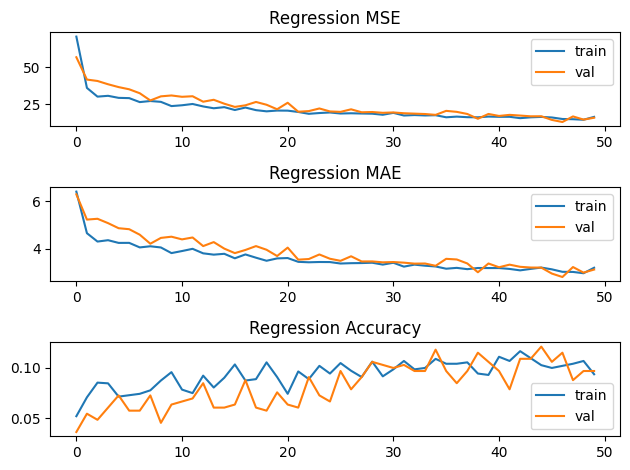

Start training...

Epoch 1


100%|██████████| 90/90 [00:11<00:00,  7.72it/s]


Train loss: 18.007 	 Train mse: 18.007 	 Train mae: 3.369, Train acc: 0.097


100%|██████████| 21/21 [00:00<00:00, 24.95it/s]


Val loss: 10.987 	 Val mse: 11.113 	 Val mae: 2.616, Val acc: 0.133

Epoch 2


100%|██████████| 90/90 [00:11<00:00,  7.72it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:11<00:00,  7.73it/s]


Train loss: 0.993 	 Train mse: 0.993 	 Train mae: 0.786, Train acc: 0.389


100%|██████████| 21/21 [00:00<00:00, 24.82it/s]


Val loss: 2.532 	 Val mse: 2.540 	 Val mae: 1.277, Val acc: 0.215
Finished training.


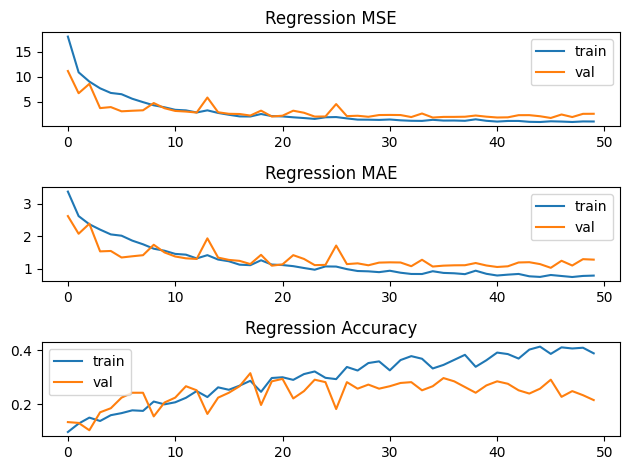

100%|██████████| 20/20 [00:00<00:00, 25.60it/s]

Test loss: 1.609 	 Test mse: 1.660 	 Test mae: 1.004, Test acc: 0.314


In [84]:
model = models.efficientnet_b2(pretrained=True)
model.classifier[1] = nn.Linear(1408, 32)
# load the best model
model.load_state_dict(torch.load('EfficientNet_B2_finetuned_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(1408, 1)

model.to(device)
# New loss function
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
model_name = 'EfficientNet_B2_regression_base_multiclass'
# Train
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistoryRegression(train_history, val_history)
# Fine tune
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = True
model_name = 'EfficientNet_B2_regression_base_multiclass_finetune'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistoryRegression(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

## MobileNet V2 from multiclass

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Start training...

Epoch 1


100%|██████████| 90/90 [00:02<00:00, 44.51it/s]


Train loss: 20.235 	 Train mse: 20.235 	 Train mae: 3.189, Train acc: 0.117


100%|██████████| 21/21 [00:00<00:00, 41.86it/s]


Val loss: 13.278 	 Val mse: 13.026 	 Val mae: 2.936, Val acc: 0.112

Epoch 2


... (192 outputs left out)

100%|██████████| 90/90 [00:02<00:00, 44.37it/s]


Train loss: 11.666 	 Train mse: 11.666 	 Train mae: 2.770, Train acc: 0.100


100%|██████████| 21/21 [00:00<00:00, 42.08it/s]


Val loss: 6.968 	 Val mse: 7.057 	 Val mae: 2.168, Val acc: 0.127
Finished training.


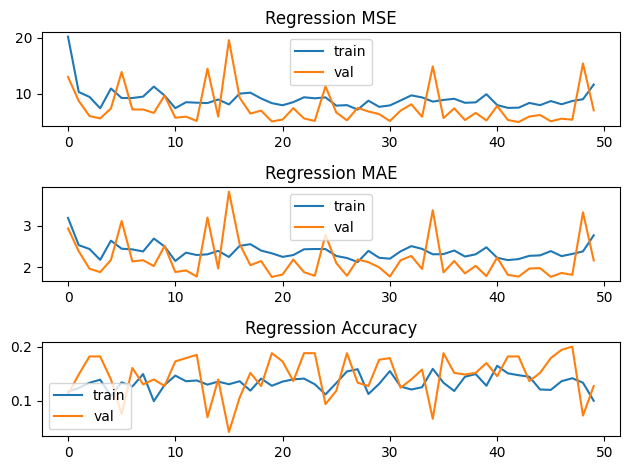

Start training...

Epoch 1


100%|██████████| 90/90 [00:05<00:00, 15.19it/s]


Train loss: 16.414 	 Train mse: 16.414 	 Train mae: 3.113, Train acc: 0.110


100%|██████████| 21/21 [00:00<00:00, 42.06it/s]


Val loss: 3.208 	 Val mse: 3.215 	 Val mae: 1.440, Val acc: 0.239

Epoch 2


100%|██████████| 90/90 [00:05<00:00, 15.19it/s]


... (191 outputs left out)

100%|██████████| 90/90 [00:05<00:00, 15.21it/s]


Train loss: 1.043 	 Train mse: 1.043 	 Train mae: 0.807, Train acc: 0.387


100%|██████████| 21/21 [00:00<00:00, 42.32it/s]


Val loss: 2.173 	 Val mse: 2.134 	 Val mae: 1.211, Val acc: 0.212
Finished training.


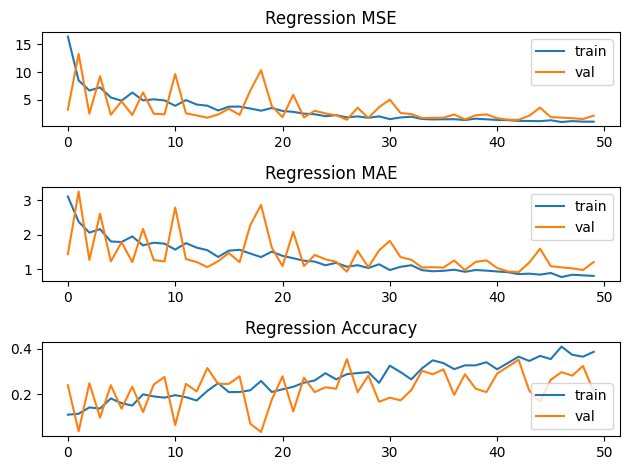

100%|██████████| 20/20 [00:00<00:00, 43.34it/s]

Test loss: 1.405 	 Test mse: 1.469 	 Test mae: 0.950, Test acc: 0.320


In [85]:
model = models.mobilenet_v2(pretrained=True)
model.classifier[1] = nn.Linear(1280, 32)
# load the best model
model.load_state_dict(torch.load('MobileNetV2_finetuned_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(1280, 1)

model.to(device)
# New loss function
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
model_name = 'MobileNet_V2_regression_base_multiclass'
# Train
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistoryRegression(train_history, val_history)
# Fine tune
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
for param in model.parameters():
    param.requires_grad = True
model_name = 'MobileNet_V2_regression_base_multiclass_finetune'
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistoryRegression(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

## ResNet50 from without pretrained

/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/mnt/windows/Data/FEUP/VCOM/VCOM/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Start training...

Epoch 1


100%|██████████| 90/90 [00:13<00:00,  6.79it/s]


Train loss: 697.326 	 Train mse: 697.326 	 Train mae: 11.192, Train acc: 0.032


100%|██████████| 21/21 [00:01<00:00, 17.94it/s]


Val loss: 77.690 	 Val mse: 76.929 	 Val mae: 7.734, Val acc: 0.027

Epoch 2


... (392 outputs left out)

100%|██████████| 90/90 [00:13<00:00,  6.78it/s]


Train loss: 2.228 	 Train mse: 2.228 	 Train mae: 1.185, Train acc: 0.264


100%|██████████| 21/21 [00:01<00:00, 17.81it/s]


Val loss: 3.589 	 Val mse: 3.601 	 Val mae: 1.513, Val acc: 0.209
Finished training.


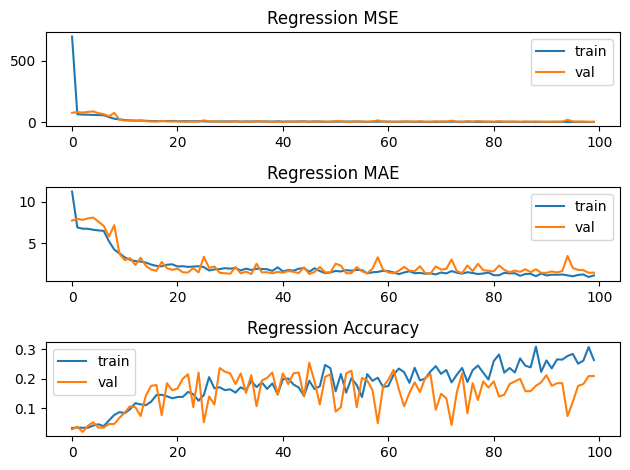

100%|██████████| 20/20 [00:01<00:00, 18.10it/s]

Test loss: 3.495 	 Test mse: 3.632 	 Test mae: 1.490, Test acc: 0.206


In [86]:
model = models.resnet50(pretrained=False)

model.fc = nn.Linear(2048, 1)

model.to(device)
# New loss function
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
model_name = 'ResNet50_regression_not_pretrained'

num_epochs *= 2 
# Train
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistoryRegression(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

## My CNN

Start training...

Epoch 1


  0%|          | 0/90 [00:00<?, ?it/s]

100%|██████████| 90/90 [00:04<00:00, 21.08it/s]


Train loss: 46.503 	 Train mse: 46.503 	 Train mae: 4.999, Train acc: 0.070


100%|██████████| 21/21 [00:00<00:00, 46.45it/s]


Val loss: 99.942 	 Val mse: 101.650 	 Val mae: 8.082, Val acc: 0.055

Epoch 2


... (392 outputs left out)

100%|██████████| 90/90 [00:04<00:00, 21.18it/s]


Train loss: 5.019 	 Train mse: 5.019 	 Train mae: 1.732, Train acc: 0.190


100%|██████████| 21/21 [00:00<00:00, 47.14it/s]


Val loss: 8.751 	 Val mse: 8.860 	 Val mae: 2.383, Val acc: 0.182
Finished training.


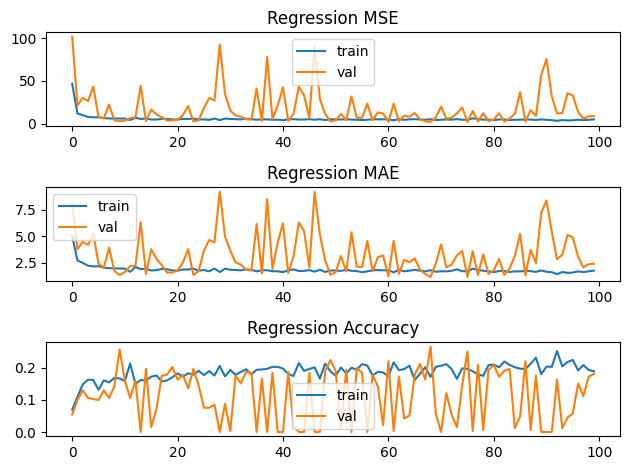

100%|██████████| 20/20 [00:00<00:00, 46.60it/s]

Test loss: 2.459 	 Test mse: 2.556 	 Test mae: 1.252, Test acc: 0.265


In [87]:
class CustomCNN(nn.Module):
    def __init__(self):
        super(CustomCNN, self).__init__()

        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 112x112
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 56x56
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 28x28
        )

        self.conv_block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 14x14
        )

        self.conv_block5 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))  # Global average pooling
        )

        self.fc = nn.Sequential(
            nn.Flatten(),                 # shape: [batch_size, 512]
            nn.Dropout(0.5),
            nn.Linear(512, 1)             # Regression output
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.fc(x)
        return x
# Instantiate the model
model = CustomCNN()
# Move the model to the device
model.to(device)
# New loss function
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
model_name = 'CustomCNN_regression'
# Train
train_history, val_history = train_regression(model, model_name, num_epochs, train_dataloader, valid_dataloader, regression_loss_fn, optimizer)
saveHistory(train_history, val_history, model_name)
plotTrainingHistoryRegression(train_history, val_history)
# Load the best model
model.load_state_dict(torch.load(model_name + '_best_model.pth')['model'])
# Evaluate model on test data
test_loss, test_mse, test_mae, test_acc = epoch_iter_regression(test_dataloader, model, regression_loss_fn, is_train=False)
print(f"Test loss: {test_loss:.3f} \t Test mse: {test_mse:.3f} \t Test mae: {test_mae:.3f}, Test acc: {test_acc:.3f}")
results = {
    'test_loss': test_loss,
    'test_mse': test_mse,
    'test_mae': test_mae,
    'test_acc': test_acc
}
torch.save(results, path + model_name + '_results.pth')
global_results[model_name] = results

## Final results

In [88]:
# Save global results and print them in a readable format
with open(path + 'global_results.pth', 'wb') as f:
    torch.save(global_results, f)
with open(path + 'global_results.txt', 'w') as f:
    for model_name, results in global_results.items():
        f.write(f"Model: {model_name}\n")
        if 'test_loss' in results:
            f.write(f"Test Loss: {results['test_loss']:.3f}\n")
        if 'test_mse' in results:
            f.write(f"Test MSE: {results['test_mse']:.3f}\n")
        if 'test_mae' in results:
            f.write(f"Test MAE: {results['test_mae']:.3f}\n")
        if 'test_acc' in results:
            f.write(f"Test Accuracy: {results['test_acc']:.3f}\n")
